<a href="https://colab.research.google.com/github/afif-af/Natural-Language-Processing/blob/main/Recurrent_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

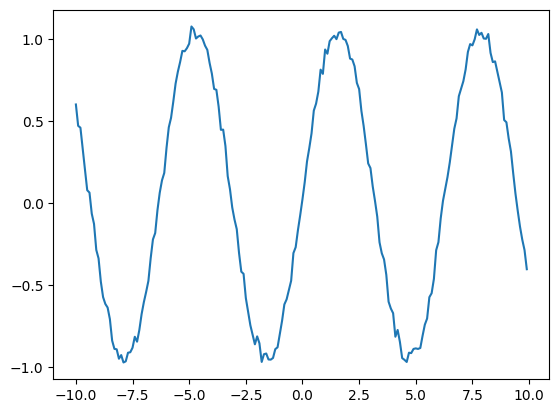

In [14]:
import numpy as np
import matplotlib.pyplot as plt

X_t=np.arange(-10, 10, 0.1)
X_t=X_t.reshape(len(X_t), -1)

Y_t=np.sin(X_t) + 0.1*np.random.rand(len(X_t),1)

plt.plot(X_t, Y_t)
plt.show()

# RNN Cell

In [44]:
import numpy as np
class RNN():
  def __init__(self, X_t, n_neurons, Activation):
    self.T      =max(X_t.shape)
    self.X_t    =X_t
    self.Y_hat  =np.zeros((self.T, 1))

    self.n_neurons =n_neurons

    self.Wx     =0.1 *np.random.randn(n_neurons, 1)
    self.Wh     =0.1 *np.random.randn(n_neurons, n_neurons)
    self.Wy     =0.1 *np.random.randn(1, n_neurons)
    self.biases =0.1 *np.random.randn(n_neurons, 1)

    self.H      =[np.zeros((n_neurons, 1)) for t in range(self.T +1)]

    self.Activation =Activation

  def forward(self):
    #initial dweights

    self.dWx    =np.zeros((self.n_neurons, 1))
    self.dWh    =np.zeros((self.n_neurons, self.n_neurons))
    self.dWy    =np.zeros((1, self.n_neurons))
    self.dbiases=np.zeros((self.n_neurons, 1))

    X_t     =self.X_t
    H       =self.H
    Y_hat   =self.Y_hat


  def RNNCell(self, xt, ht_1):

    out     = np.dot(self.Wx, xt) + np.dot(self.Wh, ht_1) + self.biases
    ht      = np.tanh(out)
    y_hat_t = np.dot(self.Wy, ht)

    return ht, y_hat_t, out

# Test RNN Cell

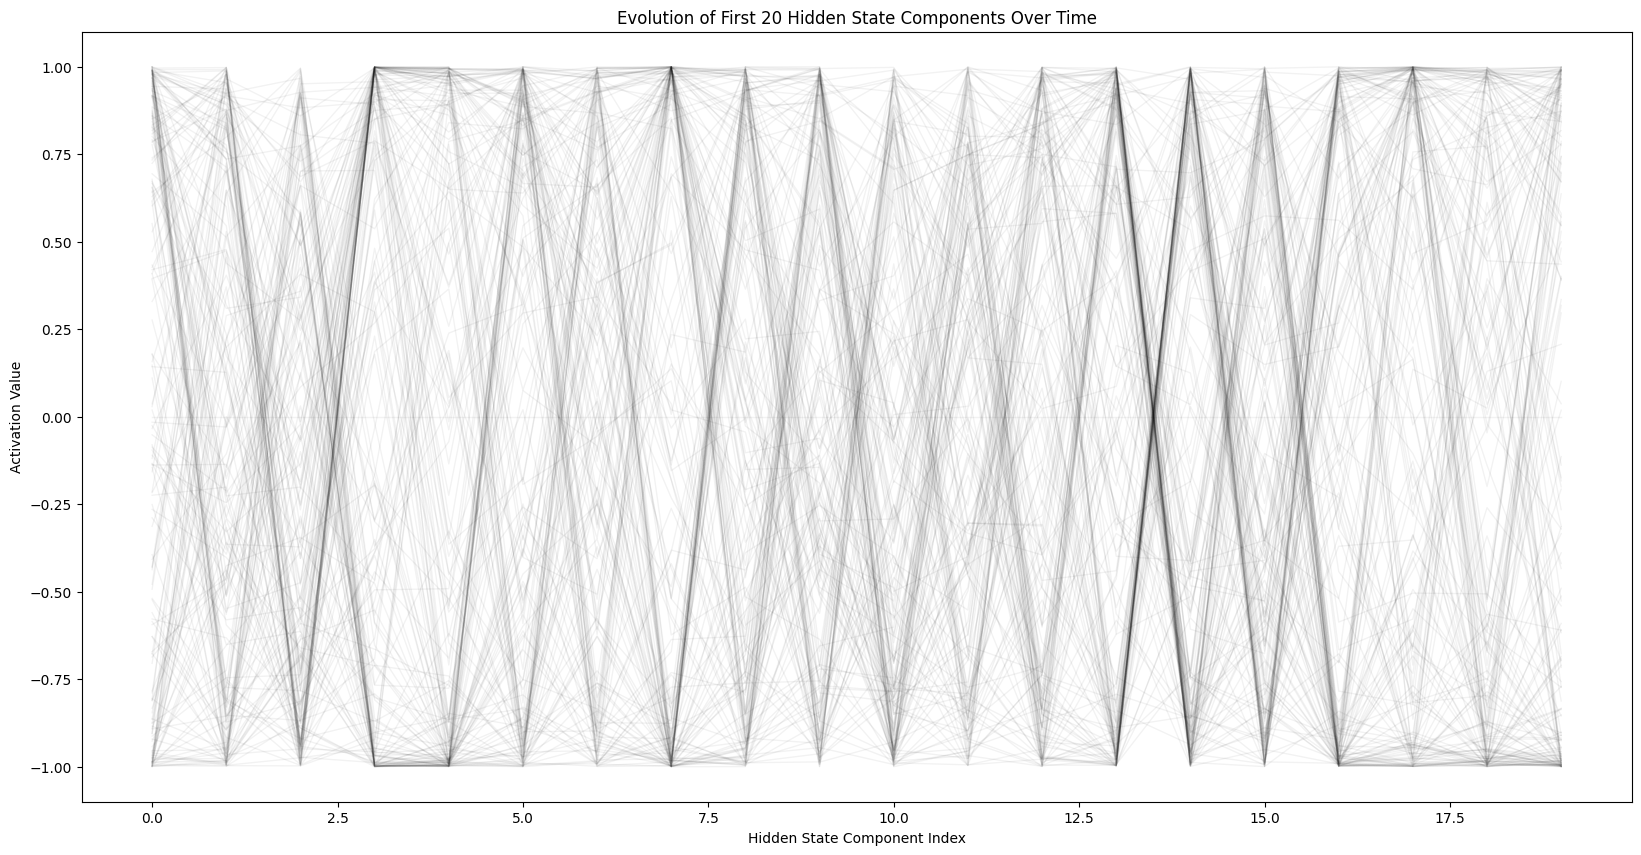

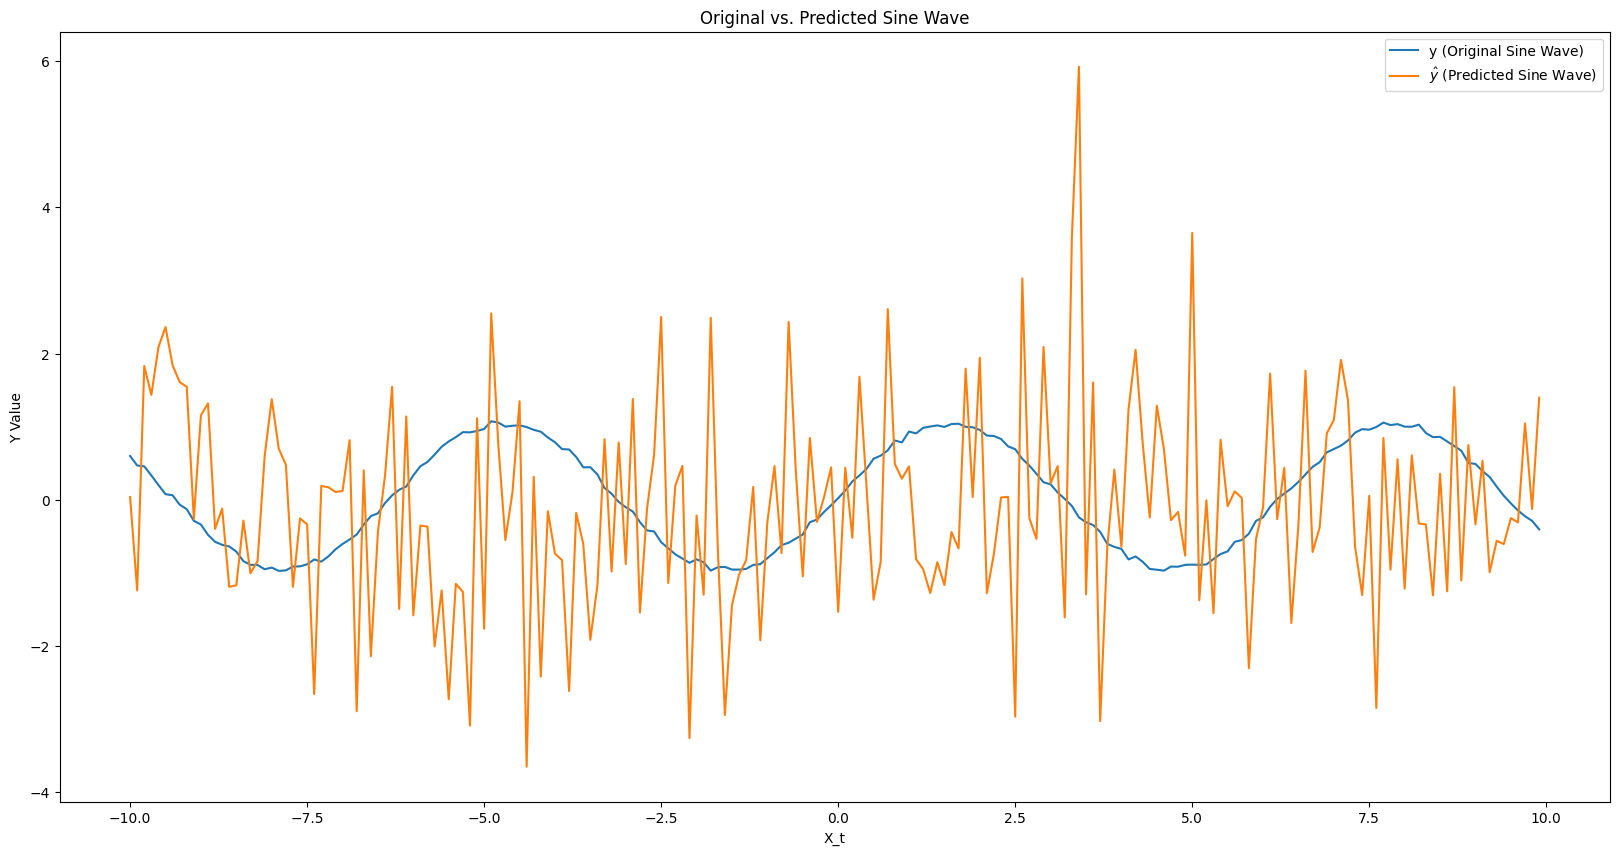

In [45]:
n_neurons =500

rnn = RNN(X_t, n_neurons)

Y_hat = rnn.Y_hat
H     = rnn.H
T     = rnn.T
ht    = H[0] #initial state vector

for t, xt in enumerate (X_t):
  xt   =xt.reshape(1,1)
  [ht, y_hat_t, out] = rnn.forward(xt, ht)
  H[t+1]   = ht
  Y_hat[t] = y_hat_t

# First Figure: Hidden State Evolution
plt.figure(figsize=(20,10))
for h in H:
  plt.plot(np.arange(20), h[0:20], 'k-', linewidth =1, alpha=0.05)
plt.title('Evolution of First 20 Hidden State Components Over Time')
plt.xlabel('Hidden State Component Index')
plt.ylabel('Activation Value')
plt.show()

# Second Figure: Original and Predicted Sine Wave
plt.figure(figsize=(20,10))
plt.plot(X_t, Y_t, label='y (Original Sine Wave)')
plt.plot(X_t, Y_hat, label='$\\hat{y}$ (Predicted Sine Wave)')
plt.title('Original vs. Predicted Sine Wave')
plt.xlabel('X_t')
plt.ylabel('Y Value')
plt.legend()
plt.show()

# Backpropagation Trough Time

In [46]:
class Tanh:

  def forward(self, inputs):
    self.output =np.tanh(inputs)
    self.inputs =inputs

  def backward(self, dvalues):
    deriv        =1 - self.output **2
    self.dinputs =np.multiply(deriv, dvalues)



In [41]:
# tanh1=Tanh()
# T=100
# activation=[Tanh() for t in range(T)]
# activation[4].backward()